In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import confusion_matrix, classification_report

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, RepeatVector, TimeDistributed, Dense

In [16]:
df = pd.read_csv("AutoEncoder/Energy Consumption/energy consumption.csv")

print(df.head())
print(df.shape)

          Timestamp  Electricity_Consumed  ...  Avg_Past_Consumption  Anomaly_Label
0  01-01-2024 00:00              0.457786  ...              0.692057              0
1  01-01-2024 00:30              0.351956  ...              0.539874              0
2  01-01-2024 01:00              0.482948  ...              0.614724              0
3  01-01-2024 01:30              0.628838  ...              0.757044              0
4  01-01-2024 02:00              0.335974  ...              0.673981              0

[5 rows x 7 columns]
(5000, 7)


In [17]:
df["Timestamp"] = pd.to_datetime(df["Timestamp"], dayfirst=True)
df = df.sort_values("Timestamp")

df = df.fillna(df.median(numeric_only=True))

X = df.drop(["Timestamp", "Anomaly_Label"], axis=1)
y = df["Anomaly_Label"]

In [18]:
scaler = MinMaxScaler()

X = scaler.fit_transform(X)

In [19]:
window_size = 24

X_seq = []
y_seq = []

for i in range(len(X) - window_size + 1):
    X_seq.append(X[i:i + window_size])
    y_seq.append(int(np.any(y.iloc[i:i + window_size])))

X_seq = np.array(X_seq)
y_seq = np.array(y_seq)

print(X_seq.shape)

(4977, 24, 5)


In [20]:
split = int(0.8 * len(X_seq))

x_train = X_seq[:split]
x_test = X_seq[split:]

y_test = y_seq[split:]

x_train = x_train[y_seq[:split] == 0]

In [22]:
model = Sequential([
    LSTM(32, activation="relu", input_shape=(24, X.shape[1])),
    RepeatVector(24),
    LSTM(32, activation="relu", return_sequences=True),
    TimeDistributed(Dense(X.shape[1]))
])

model.compile(optimizer="adam", loss="mse")

model.summary()

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_2 (LSTM)                   │ (None, 32)             │         4,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ repeat_vector_1 (RepeatVector)  │ (None, 24, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 24, 32)         │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_1              │ (None, 24, 5)          │           165 │
│ (TimeDistributed)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 13,349 (52.14 KB)

 Trainable params: 13,349 (52.14 KB)

 Non-trainable params: 0 (0.00 B)

In [23]:
history = model.fit(
    x_train, x_train,
    epochs=10,
    batch_size=32,
    validation_split=0.1
)

Epoch 1/10
51/51 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - loss: 0.0635 - val_loss: 0.0245
Epoch 2/10
51/51 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0232 - val_loss: 0.0203
Epoch 3/10
51/51 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0197 - val_loss: 0.0184
Epoch 4/10
51/51 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0183 - val_loss: 0.0179
Epoch 5/10
51/51 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0179 - val_loss: 0.0179
Epoch 6/10
51/51 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0178 - val_loss: 0.0174
Epoch 7/10
51/51 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0176 - val_loss: 0.0171
Epoch 8/10
51/51 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0175 - val_loss: 0.0172
Epoch 9/10
51/51 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0174 - val_loss: 0.0170
Epoch 10/10
51/51 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0174 - val_loss: 0.0170


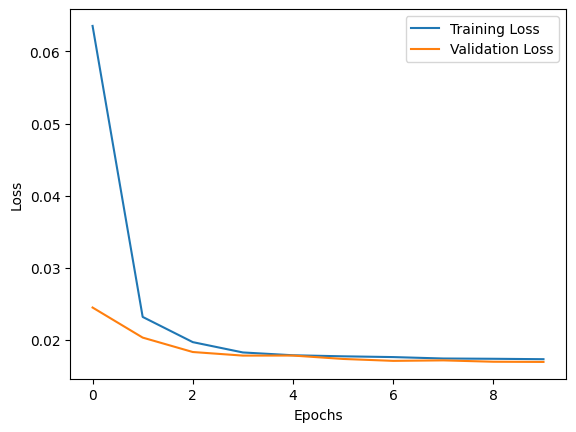

In [24]:
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

In [25]:
train_pred = model.predict(x_train)

train_error = np.mean(np.square(x_train - train_pred), axis=(1, 2))

threshold = np.mean(train_error) + 3 * np.std(train_error)

print("Threshold:", threshold)

56/56 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
Threshold: 0.02432083453835793


In [26]:
test_pred = model.predict(x_test)

test_error = np.mean(np.square(x_test - test_pred), axis=(1, 2))

y_pred = (test_error > threshold).astype(int)

print("Detected Anomalies:", np.sum(y_pred))

32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
Detected Anomalies: 28


In [27]:
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))


Confusion Matrix:
[[484   0]
 [484  28]]

Classification Report:
              precision    recall  f1-score   support

           0       0.50      1.00      0.67       484
           1       1.00      0.05      0.10       512

    accuracy                           0.51       996
   macro avg       0.75      0.53      0.39       996
weighted avg       0.76      0.51      0.38       996

